In [123]:
# Importing Library
import pandas as pd  # Cleaning/Manupulating/Analysing of data
import numpy as np  # Numerical calculation
import seaborn as sns  # Visualization
import matplotlib.pyplot as plt  # Visualization

In [124]:
# Importing Dataset
df = pd.read_csv("/content/Car_details.csv")

In [125]:
# Understanding Dataset
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [126]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [127]:
# Summary of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


In [128]:
df.duplicated().sum()

np.int64(1202)

In [129]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,221
engine,221


In [130]:
df.shape

(8128, 13)

In [131]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats'],
      dtype='object')

In [132]:
for col in df.columns:
  if df[col].dtype == 'object':
    df[col] = df[col].fillna(df[col].mode()[0])
  else:
    df[col] = df[col].fillna(df[col].median())

In [133]:
df = df.drop_duplicates()

In [134]:
# Rechecking duplicated values
df.duplicated().sum()

np.int64(0)

In [135]:
# Rechecking Missing Values
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,0
engine,0


In [137]:
# Converting objectinve dtype to Numerical dtype
# Identify object columns:
df.select_dtypes(include = 'object').columns

df.select_dtypes(include = 'object').columns


Index(['name', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage',
       'engine', 'max_power', 'torque'],
      dtype='object')

In [138]:
# Remove unnecessary columns:
df.drop(['name', 'owner'], axis = 1, inplace = True)

In [139]:
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,mileage,engine,max_power,torque,seats
0,2014,450000,145500,Diesel,Individual,Manual,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,2014,370000,120000,Diesel,Individual,Manual,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,2006,158000,140000,Petrol,Individual,Manual,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,2010,225000,127000,Diesel,Individual,Manual,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,2007,130000,120000,Petrol,Individual,Manual,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [140]:
# Convert categorical data into numerical data
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

# Loop over columns that are actually categorical ('object' dtype)
for col in df.select_dtypes(include='object').columns:
  df[col] = le.fit_transform(df[col])

In [141]:
# verify
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           6926 non-null   int64  
 1   selling_price  6926 non-null   int64  
 2   km_driven      6926 non-null   int64  
 3   fuel           6926 non-null   int64  
 4   seller_type    6926 non-null   int64  
 5   transmission   6926 non-null   int64  
 6   mileage        6926 non-null   int64  
 7   engine         6926 non-null   int64  
 8   max_power      6926 non-null   int64  
 9   torque         6926 non-null   int64  
 10  seats          6926 non-null   float64
dtypes: float64(1), int64(10)
memory usage: 649.3 KB


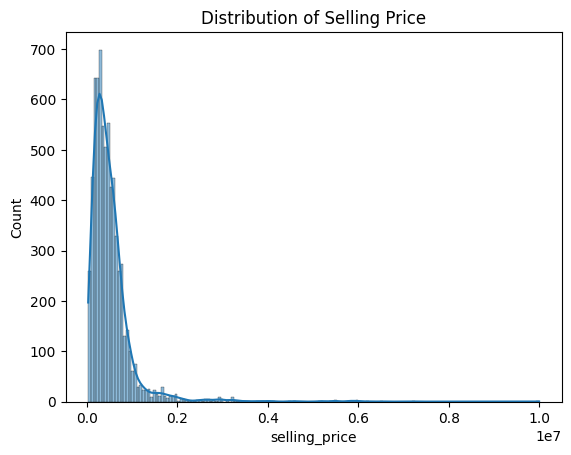

In [143]:
# Univariate analysis
sns.histplot(df['selling_price'], kde = True)
plt.title('Distribution of Selling Price')
plt.show()

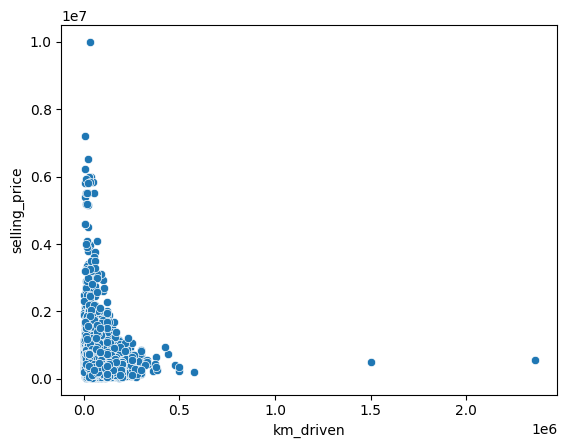

In [146]:
# Bivariate analysis
sns.scatterplot(x = 'km_driven', y = 'selling_price', data = df)
plt.show()

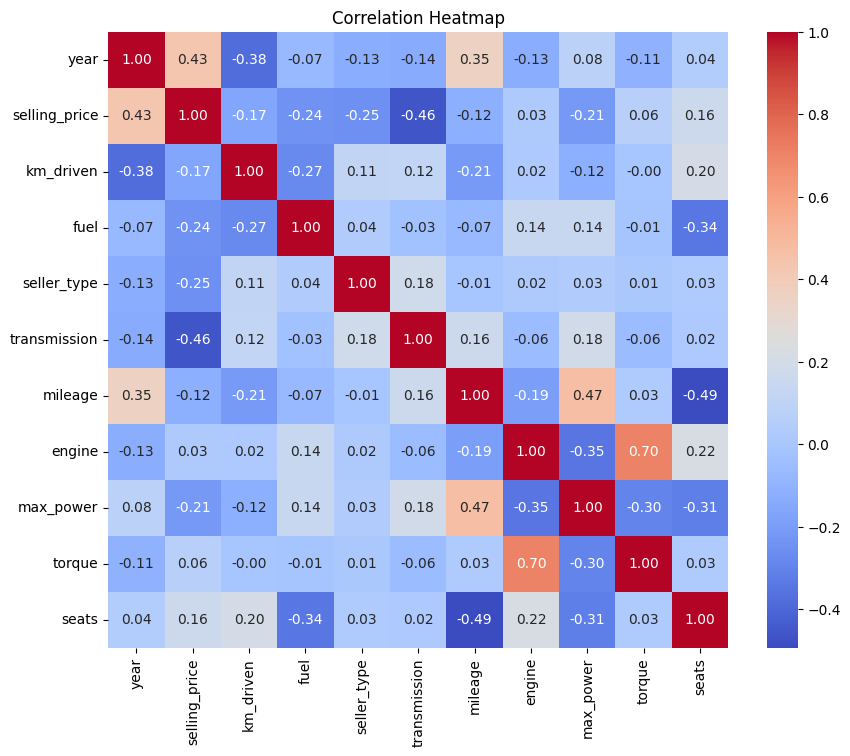

In [147]:
# Multi-variate Analysis
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt ='.2f')
plt.title("Correlation Heatmap")
plt.show()

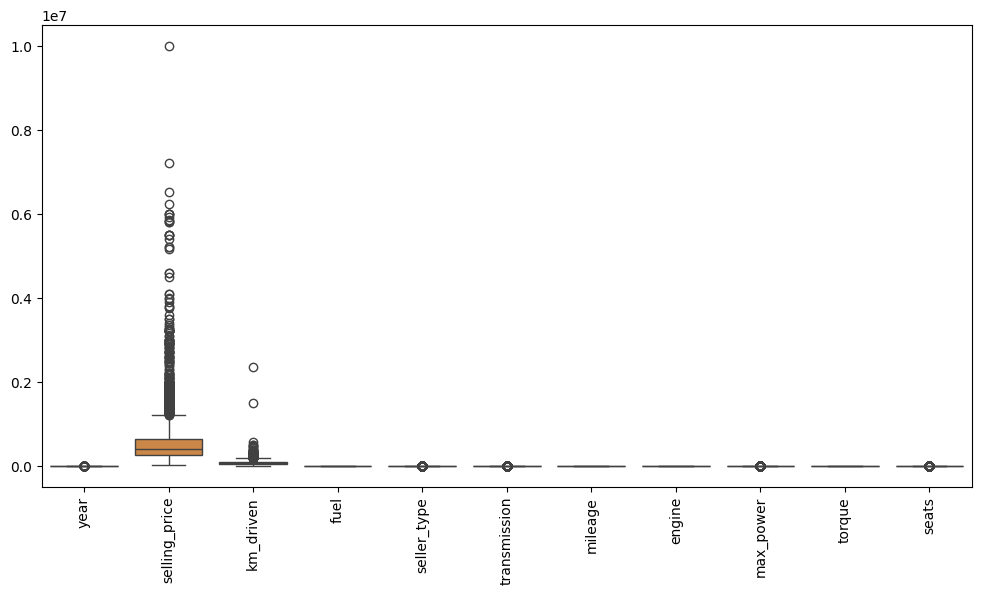

In [148]:
# Outliers Prediction
plt.figure(figsize=(12, 6))
sns.boxplot(data=df)
plt.xticks(rotation = 90)
plt.show()

In [149]:
# Outlier Treatment
for col in df.columns:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  df[col] = np.where((df[col] < lower_bound) | (df[col] > upper_bound), df[col].median(), df[col])

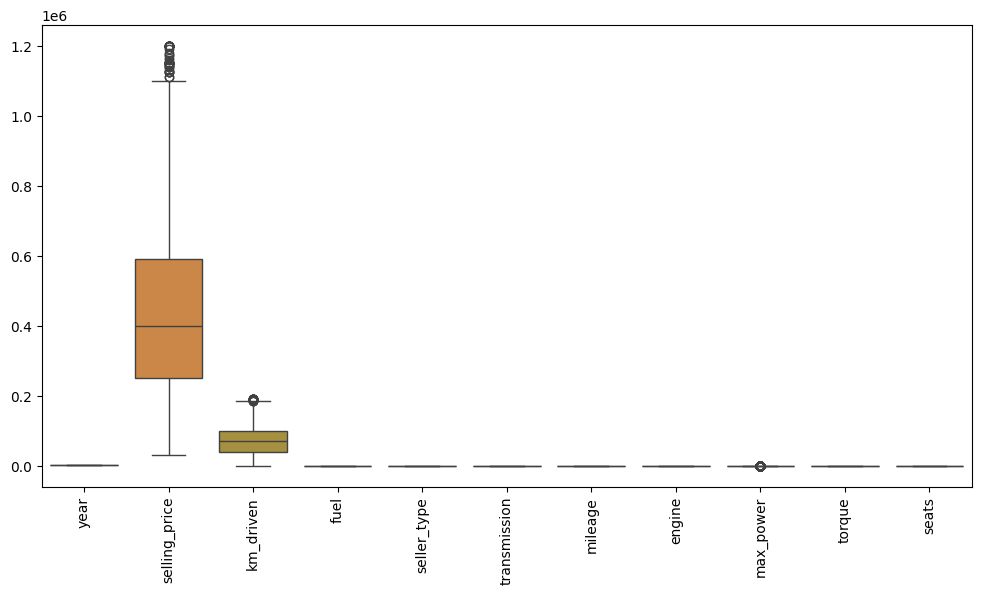

In [150]:
# Recheck the Outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=df)
plt.xticks(rotation = 90)
plt.show()

In [151]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           6926 non-null   float64
 1   selling_price  6926 non-null   float64
 2   km_driven      6926 non-null   float64
 3   fuel           6926 non-null   float64
 4   seller_type    6926 non-null   float64
 5   transmission   6926 non-null   float64
 6   mileage        6926 non-null   float64
 7   engine         6926 non-null   float64
 8   max_power      6926 non-null   float64
 9   torque         6926 non-null   float64
 10  seats          6926 non-null   float64
dtypes: float64(11)
memory usage: 649.3 KB
